### Normalization

Normalization is a feature-scaling process that changes numerical feature values to a chosen scale. It is useful when features have different units or ranges, especially for algorithms that rely on distances or numerical optimization.

This notebook demonstrates four scaling techniques using the **Alcohol** and **Mallic acid** features from the Wine dataset: Min-Max Scaling, Mean Normalization, MaxAbs Scaling, and Robust Scaling. Each technique is implemented using Scikit-learn where available and with a custom Python class.

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 

In [2]:
df = pd.read_csv('Datasets/wine_data.csv', header=None, usecols=[0,1,2])
df.columns=['Class label', 'Alcohol', 'Mallic acid']
df

,Class label,Alcohol,Mallic acid
0,1,14.23,1.71
1,1,13.20,1.78
2,1,13.16,2.36
3,1,14.37,1.95
4,1,13.24,2.59
...,...,...,...
173,3,13.71,5.65
174,3,13.40,3.91
175,3,13.27,4.28
176,3,13.17,2.59


<Axes: xlabel='Alcohol', ylabel='Mallic acid'>

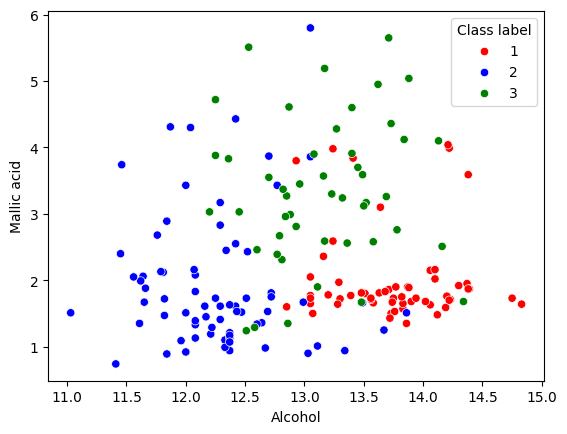

In [3]:
color_dict = {1:'red', 3:'green', 2:'blue'}
sns.scatterplot(x=df['Alcohol'], y=df['Mallic acid'], hue=df['Class label'], palette=color_dict)

In [4]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(df.drop('Class label', axis=1), df['Class label'], test_size=0.2, random_state=0)

X_train.shape, X_test.shape

((142, 2), (36, 2))

### Min-Max Scaling

Min-Max Scaling transforms each feature to a specified range. By default, `MinMaxScaler` maps values to the range 0 to 1.

$$X_{scaled} = \frac{X - X_{min}}{X_{max} - X_{min}}$$

The minimum becomes 0 and the maximum becomes 1 in the data used to fit the scaler. Values in new data can fall outside this range if they are smaller or larger than the training data's minimum and maximum.

#### Using Sklearn class

In [5]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

In [6]:
# fit the scalar to the train test, it will learn parameters 
scaler.fit(X_train)

MinMaxScaler()

In [7]:
scaler.data_min_

array([11.03,  0.74])

In [8]:
scaler.data_max_

array([14.75,  5.65])

In [9]:
# transform train and test sets 
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [10]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

In [11]:
np.round(X_train.describe(), 2)

,Alcohol,Mallic acid
count,142.00,142.00
mean,12.98,2.37
std,0.81,1.12
min,11.03,0.74
25%,12.35,1.60
50%,13.04,1.90
75%,13.64,3.22
max,14.75,5.65


In [12]:
np.round(X_train_scaled.describe(), 2)

,Alcohol,Mallic acid
count,142.00,142.00
mean,0.53,0.33
std,0.22,0.23
min,0.00,0.00
25%,0.35,0.18
50%,0.54,0.24
75%,0.70,0.51
max,1.00,1.00


Text(0.5, 1.0, 'After Scaling')

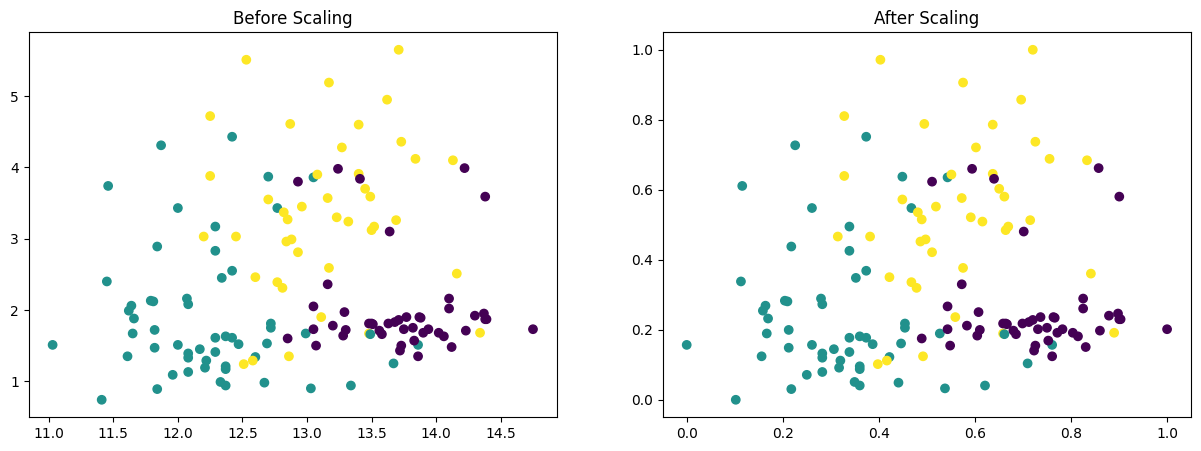

In [13]:
fig, ax = plt.subplots(ncols=2, figsize=(15,5))

ax[0].scatter(X_train['Alcohol'], X_train['Mallic acid'], c=y_train)
ax[0].set_title('Before Scaling')

ax[1].scatter(X_train_scaled['Alcohol'], X_train_scaled['Mallic acid'], c=y_train)
ax[1].set_title('After Scaling')

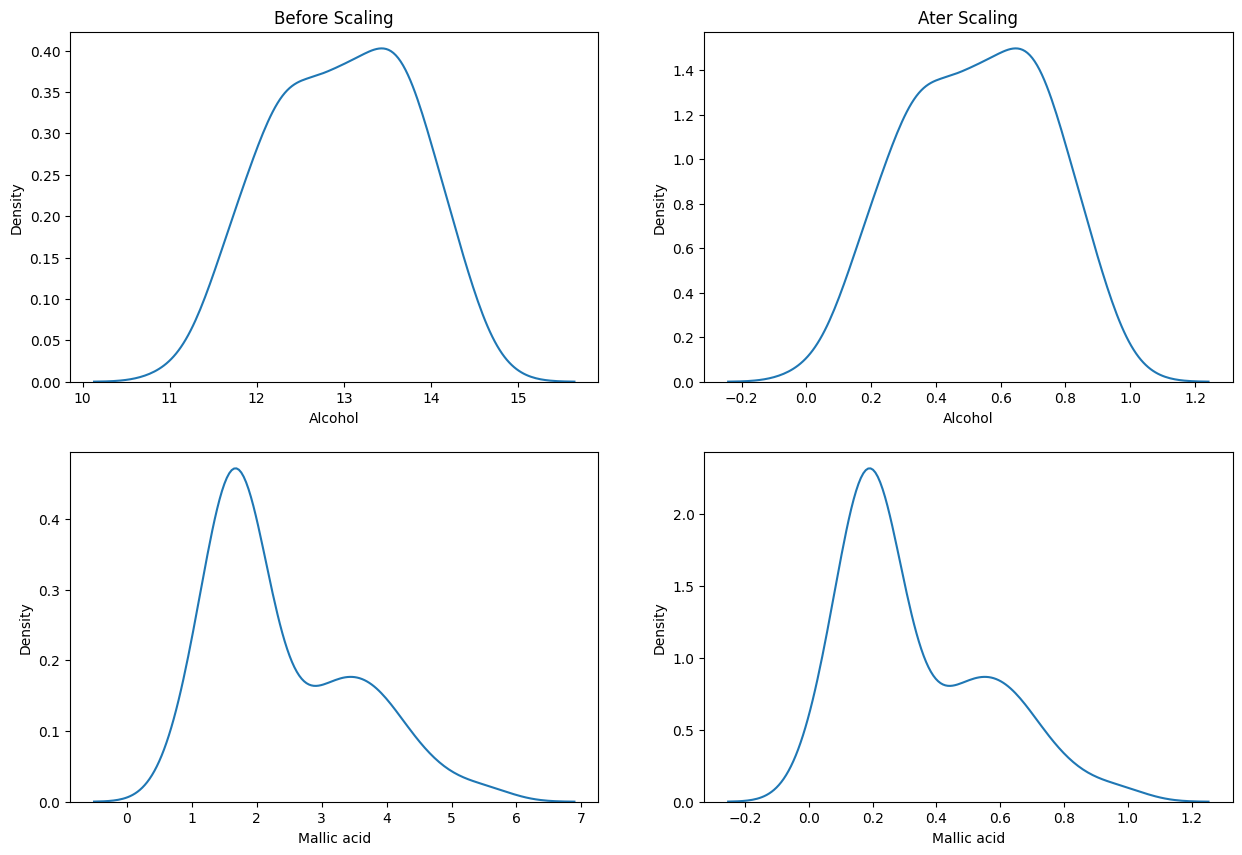

In [14]:
fig, ax = plt.subplots(ncols=2, nrows=2, figsize=(15,10))

# before scaling 
ax[0,0].set_title('Before Scaling')
sns.kdeplot(X_train['Alcohol'], ax = ax[0,0])
sns.kdeplot(X_train['Mallic acid'], ax = ax[1,0])

# after scaling 
ax[0,1].set_title('Ater Scaling')
sns.kdeplot(X_train_scaled['Alcohol'], ax = ax[0,1])
sns.kdeplot(X_train_scaled['Mallic acid'], ax = ax[1,1])

plt.show()

#### Using Own class 

In [15]:
class MinMaxScaling: 

    def __init__(self): 
        self.min = None
        self.max = None 

    def fit(self, X_train): 
        self.min = X_train.min().values
        self.max = X_train.max().values

    def transform(self, data): 
        scaled_df = (data - self.min) / (self.max - self.min)
        return scaled_df

In [16]:
myscaler = MinMaxScaling()

In [17]:
myscaler.fit(X_train)

In [18]:
myscaler.min

array([11.03,  0.74])

In [19]:
myscaler.max

array([14.75,  5.65])

In [20]:
# transform train and test sets 
X_train_scaled = myscaler.transform(X_train)
X_test_scaled = myscaler.transform(X_test)

In [21]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

In [22]:
np.round(X_train.describe(), 2)

,Alcohol,Mallic acid
count,142.00,142.00
mean,12.98,2.37
std,0.81,1.12
min,11.03,0.74
25%,12.35,1.60
50%,13.04,1.90
75%,13.64,3.22
max,14.75,5.65


In [23]:
np.round(X_train_scaled.describe(), 2)

,Alcohol,Mallic acid
count,142.00,142.00
mean,0.53,0.33
std,0.22,0.23
min,0.00,0.00
25%,0.35,0.18
50%,0.54,0.24
75%,0.70,0.51
max,1.00,1.00


### Mean Normalization

Mean Normalization subtracts the feature mean and divides by the feature range (maximum minus minimum).

$$X_{scaled} = \frac{X - \mu}{X_{max} - X_{min}}$$

Here, $\mu$ is the feature mean. The transformed values are centered around zero, but they are not necessarily bounded between -1 and 1.

#### Using Own Class , no class in sklearn for this

In [24]:
class MeanNormalization: 

    def __init__(self): 
        self.min = None
        self.max = None 
        self.mean = None

    def fit(self, X_train): 
        self.min = X_train.min().values
        self.max = X_train.max().values
        self.mean = X_train.mean().values

    def transform(self, data): 
        scaled_df = (data - self.mean) / (self.max - self.min)
        return scaled_df

In [25]:
mean_norm = MeanNormalization()

In [26]:
mean_norm.fit(X_train)

In [27]:
mean_norm.min

array([11.03,  0.74])

In [28]:
mean_norm.max

array([14.75,  5.65])

In [29]:
mean_norm.mean

array([12.98485915,  2.37260563])

In [30]:
# transform train and test sets 
X_train_scaled = mean_norm.transform(X_train)
X_test_scaled = mean_norm.transform(X_test)

In [31]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

In [32]:
np.round(X_train.describe(), 2)

,Alcohol,Mallic acid
count,142.00,142.00
mean,12.98,2.37
std,0.81,1.12
min,11.03,0.74
25%,12.35,1.60
50%,13.04,1.90
75%,13.64,3.22
max,14.75,5.65


In [33]:
np.round(X_test_scaled.describe(), 2)

,Alcohol,Mallic acid
count,36.00,36.00
mean,0.02,-0.04
std,0.23,0.23
min,-0.38,-0.30
25%,-0.17,-0.16
50%,0.02,-0.13
75%,0.21,0.04
max,0.50,0.70


Text(0.5, 1.0, 'After Scaling')

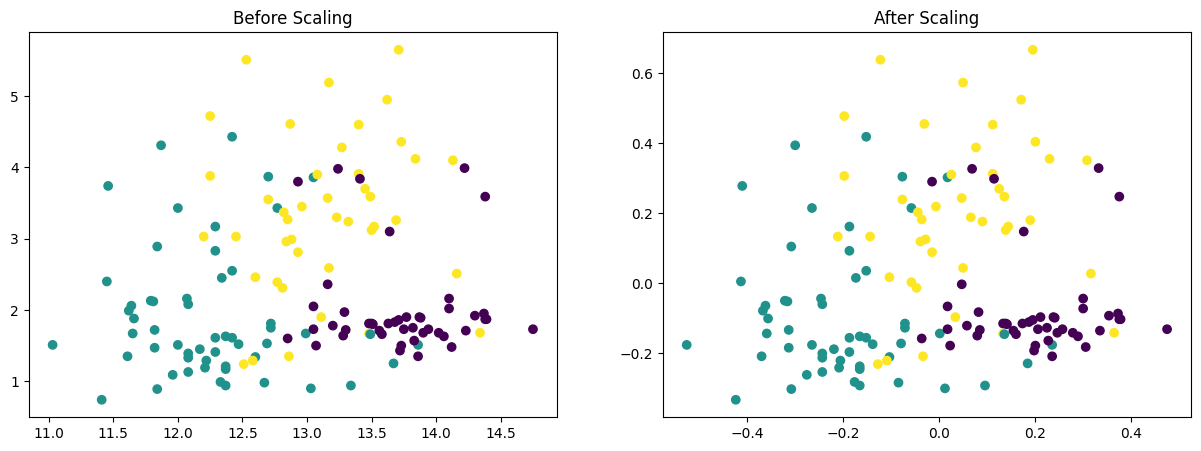

In [34]:
fig, ax = plt.subplots(ncols=2, figsize=(15,5))

ax[0].scatter(X_train['Alcohol'], X_train['Mallic acid'], c=y_train)
ax[0].set_title('Before Scaling')

ax[1].scatter(X_train_scaled['Alcohol'], X_train_scaled['Mallic acid'], c=y_train)
ax[1].set_title('After Scaling')

### MaxAbs Scaling

MaxAbs Scaling divides each feature by its maximum absolute value.

$$X_{scaled} = \frac{X}{|X|_{max}}$$

It scales values to the range -1 to 1 while preserving zero values and the sparsity of sparse data. It does not shift or center the data.

#### Using sklearn class 

In [35]:
from sklearn.preprocessing import MaxAbsScaler

In [36]:
max_abs_sc = MaxAbsScaler()

In [37]:
max_abs_sc.fit(X_train)

MaxAbsScaler()

In [38]:
# transform train and test sets 
X_train_scaled = max_abs_sc.transform(X_train)
X_test_scaled = max_abs_sc.transform(X_test)

In [39]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

In [40]:
np.round(X_train.describe(), 2)

,Alcohol,Mallic acid
count,142.00,142.00
mean,12.98,2.37
std,0.81,1.12
min,11.03,0.74
25%,12.35,1.60
50%,13.04,1.90
75%,13.64,3.22
max,14.75,5.65


In [41]:
np.round(X_train_scaled.describe(), 2)

,Alcohol,Mallic acid
count,142.00,142.00
mean,0.88,0.42
std,0.05,0.20
min,0.75,0.13
25%,0.84,0.28
50%,0.88,0.34
75%,0.92,0.57
max,1.00,1.00


#### Using Our own class 

In [42]:
class MaxAbsScaling: 

    def __init__(self): 
        self.max = None 

    def fit(self, X_train): 
        self.max = X_train.abs().max().values

    def transform(self, data): 
        scaled_df = data / self.max 
        return scaled_df

In [43]:
my_max_abs_sc = MaxAbsScaling()

In [44]:
my_max_abs_sc.fit(X_train)

In [45]:
# transform train and test sets 
X_train_scaled = my_max_abs_sc.transform(X_train)
X_test_scaled = my_max_abs_sc.transform(X_test)

In [46]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

In [47]:
np.round(X_train.describe(), 2)

,Alcohol,Mallic acid
count,142.00,142.00
mean,12.98,2.37
std,0.81,1.12
min,11.03,0.74
25%,12.35,1.60
50%,13.04,1.90
75%,13.64,3.22
max,14.75,5.65


In [48]:
np.round(X_train_scaled.describe(), 2)

,Alcohol,Mallic acid
count,142.00,142.00
mean,0.88,0.42
std,0.05,0.20
min,0.75,0.13
25%,0.84,0.28
50%,0.88,0.34
75%,0.92,0.57
max,1.00,1.00


### Robust Scaling

Robust Scaling subtracts the median and divides by the interquartile range (IQR).

$$X_{scaled} = \frac{X - \text{Median}}{Q_3 - Q_1}$$

The IQR is the difference between the 75th percentile ($Q_3$) and the 25th percentile ($Q_1$). Because it uses the median and IQR instead of the mean and standard deviation, it is less sensitive to outliers.

#### Using sklearn 

In [49]:
from sklearn.preprocessing import RobustScaler

In [50]:
robust_sc = RobustScaler()

In [51]:
robust_sc.fit(X_train)

RobustScaler()

In [52]:
robust_sc.center_

array([13.04 ,  1.895])

In [53]:
# transform train and test sets 
X_train_scaled = robust_sc.transform(X_train)
X_test_scaled = robust_sc.transform(X_test)

In [54]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

In [55]:
np.round(X_train.describe(), 2)

,Alcohol,Mallic acid
count,142.00,142.00
mean,12.98,2.37
std,0.81,1.12
min,11.03,0.74
25%,12.35,1.60
50%,13.04,1.90
75%,13.64,3.22
max,14.75,5.65


In [56]:
np.round(X_train_scaled.describe(), 2)

,Alcohol,Mallic acid
count,142.00,142.00
mean,-0.04,0.29
std,0.63,0.69
min,-1.56,-0.71
25%,-0.54,-0.18
50%,0.00,-0.00
75%,0.46,0.82
max,1.33,2.32


#### Using a Custom Class 

In [57]:
class RobustScaling: 

    def __init__(self): 
        self.median = None
        self.iqr = None 

    def fit(self, X_train): 
        self.median = X_train.median().values
        self.iqr = X_train.quantile(0.75).values - X_train.quantile(0.25).values

    def transform(self, data): 
        scaled_df = (data - self.median) / self.iqr
        return scaled_df

In [58]:
my_robust_sc = RobustScaling()

In [59]:
my_robust_sc.fit(X_train)

In [60]:
my_robust_sc.iqr

array([1.29, 1.62])

In [61]:
my_robust_sc.median

array([13.04 ,  1.895])

### Standardization vs Normalization

Both standardization and normalization are feature-scaling approaches, but they use different statistics and produce different scales.

| Aspect | Standardization | Normalization |
|:--|:--|:--|
| Main idea | Centers values around the mean and scales by standard deviation | Rescales values using statistics such as minimum, maximum, median, or range |
| Common formula | $z = \frac{x - \mu}{\sigma}$ | Min-Max: $x' = \frac{x - x_{min}}{x_{max} - x_{min}}$ |
| Typical result | Mean near 0 and standard deviation near 1 | Often a fixed range, such as 0 to 1; depends on the method |
| Outlier sensitivity | Sensitive to outliers because mean and standard deviation are affected | Depends on the method; Min-Max is sensitive, while Robust Scaling is less sensitive |
| Common use | Algorithms affected by feature magnitude and distribution | Distance-based algorithms and workflows that benefit from bounded or comparable feature ranges |

**Which should you use ?**

- Use **Standardization** when an algorithm benefits from features centered around zero and scaled by standard deviation.
- Use **Min-Max Scaling** when you need values mapped to a defined range, commonly 0 to 1.
- Use **Robust Scaling** when the data contains substantial outliers.
- Use **MaxAbs Scaling** when you want to preserve zero values and the sparsity of sparse data.

> Note: In machine learning, the word *normalization* is sometimes used broadly to mean any feature scaling. In this notebook, it refers to the specific normalization methods demonstrated above.

**Important :** Always split the dataset first, fit the scaler using only the training features, and use that fitted scaler to transform both training and test features. Never fit a scaler separately on the test set.